# 3. Cálculos: banho quente em famílias de baixa renda
**Citizen Assist AI — contribuição de Soluções em Energias Renováveis e Sustentáveis**

Este notebook compara, para a **mesma necessidade** (banho quente de uma família de 3 pessoas em São Paulo) e o **mesmo período** (12 meses):

| | Cenário | Tipo |
|---|---|---|
| Base | Banho de 10 min, chuveiro elétrico na posição inverno o ano todo | situação atual |
| A | Banho de 5 min e posição verão de outubro a março | economia de energia (custo zero) |
| B | Aquecedor solar de água, com o chuveiro elétrico só de apoio | fonte renovável |

Todos os números vêm de `dados/premissas.csv` (fontes em `02_dados_e_fontes.md`). As contas ficam em `calculadora_energia.py`, **o mesmo módulo que o assistente usa**. Assim, o que o assistente responde é exatamente o que está calculado aqui.

> ⚠️ Todos os resultados são **estimativas** baseadas nas premissas. O consumo real depende do chuveiro, dos hábitos e do clima.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import calculadora_energia as ce

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
Path("figuras").mkdir(exist_ok=True)
Path("resultados").mkdir(exist_ok=True)

pr = ce.carregar_premissas()
brl = lambda x: f"{x:,.0f}".replace(",", ".")  # formato brasileiro: 2.300
tabela = pd.read_csv(ce.ARQUIVO_PREMISSAS)
tabela[["id", "parametro", "valor", "unidade", "tipo"]]

,id,parametro,valor,unidade,tipo
0,P01,Moradores por domicílio (Brasil),2.79,pessoas,OFICIAL (via imprensa)
1,P02,Pessoas na família de referência,3,pessoas,PREMISSA
2,P03,Banhos por pessoa por dia,1,banho/dia,PREMISSA
3,P04,Duração do banho - situação base,10,min,SECUNDÁRIA
4,P05,Duração do banho - alternativa A,5,min,SECUNDÁRIA
5,P06,Potência do chuveiro - posição inverno,5500,W,SECUNDÁRIA
6,P07,Redução de potência na posição verão,35,%,ESTIMADO
7,P08,Meses na posição verão (alternativa A),6,meses,PREMISSA
8,P09,Dias por mês,30,dias,PREMISSA
9,P10,Tarifa B1 Enel SP sem impostos (TE+TUSD),0.78938,R$/kWh,SECUNDÁRIA


## 3.1 Conceitos e energia de um banho
**Energia (kWh) = Potência (kW) × Tempo (h)**

Um chuveiro de 5.500 W ligado por 10 minutos:

In [2]:
pot = ce.v(pr, "P06")
for minutos in (5, 10, 15):
    print(f"{minutos:>2} min a {pot:.0f} W -> {ce.energia_banho_kwh(pot, minutos):.3f} kWh por banho")

 5 min a 5500 W -> 0.458 kWh por banho
10 min a 5500 W -> 0.917 kWh por banho
15 min a 5500 W -> 1.375 kWh por banho


### Conferência física: o resultado faz sentido?
A energia elétrica vira calor na água: **Q = m · c · ΔT**. Se a água entra a ~20 °C e sai a ~40 °C (ΔT = 20 °C), quantos litros um banho de 10 min consegue aquecer?

In [3]:
e10 = ce.energia_banho_kwh(pot, ce.v(pr, "P04"))
litros = ce.litros_aquecidos(e10, ce.v(pr, "P22"), ce.v(pr, "P23"))
print(f"Energia: {e10:.3f} kWh = {e10*3.6:.2f} MJ")
print(f"Água aquecida em 20 °C: {litros:.0f} litros -> vazão de {litros/10:.1f} L/min")

Energia: 0.917 kWh = 3.30 MJ
Água aquecida em 20 °C: 39 litros -> vazão de 3.9 L/min


Uma vazão de cerca de 4 L/min está dentro da faixa de chuveiros elétricos usada por Altoé et al. (2012), de 3 a 5 L/min. Então a potência e o tempo escolhidos são fisicamente coerentes.

## 3.2 Consumo mês a mês (kWh)
- **A:** a potência cai 35% nos meses em que se usa a posição verão (out–mar).
- **B:** a fração solar anual de 70% (NBR 15569) é ajustada pelo sol de cada estação. No inverno o sol é mais fraco e o chuveiro de apoio trabalha mais.

In [4]:
mensal = pd.DataFrame(ce.cenarios_mensais(pr))
mensal["fracao_solar_b"] = (mensal["fracao_solar_b"] * 100).round(1)
mensal.rename(columns={"base_kwh": "Base (kWh)", "a_kwh": "A (kWh)", "b_kwh": "B (kWh)", "ab_kwh": "A+B (kWh)",
                       "fracao_solar_b": "Fração solar B (%)"})

,mes,estacao,Base (kWh),A (kWh),B (kWh),A+B (kWh),Fração solar B (%)
0,jan,verão,82.50,26.81,15.19,4.94,81.60
1,fev,verão,82.50,26.81,15.19,4.94,81.60
2,mar,outono,82.50,26.81,32.55,10.58,60.50
3,abr,outono,82.50,41.25,32.55,16.28,60.50
4,mai,outono,82.50,41.25,32.55,16.28,60.50
5,jun,inverno,82.50,41.25,34.94,17.47,57.60
6,jul,inverno,82.50,41.25,34.94,17.47,57.60
7,ago,inverno,82.50,41.25,34.94,17.47,57.60
8,set,primavera,82.50,41.25,16.45,8.22,80.10
9,out,primavera,82.50,26.81,16.45,5.34,80.10


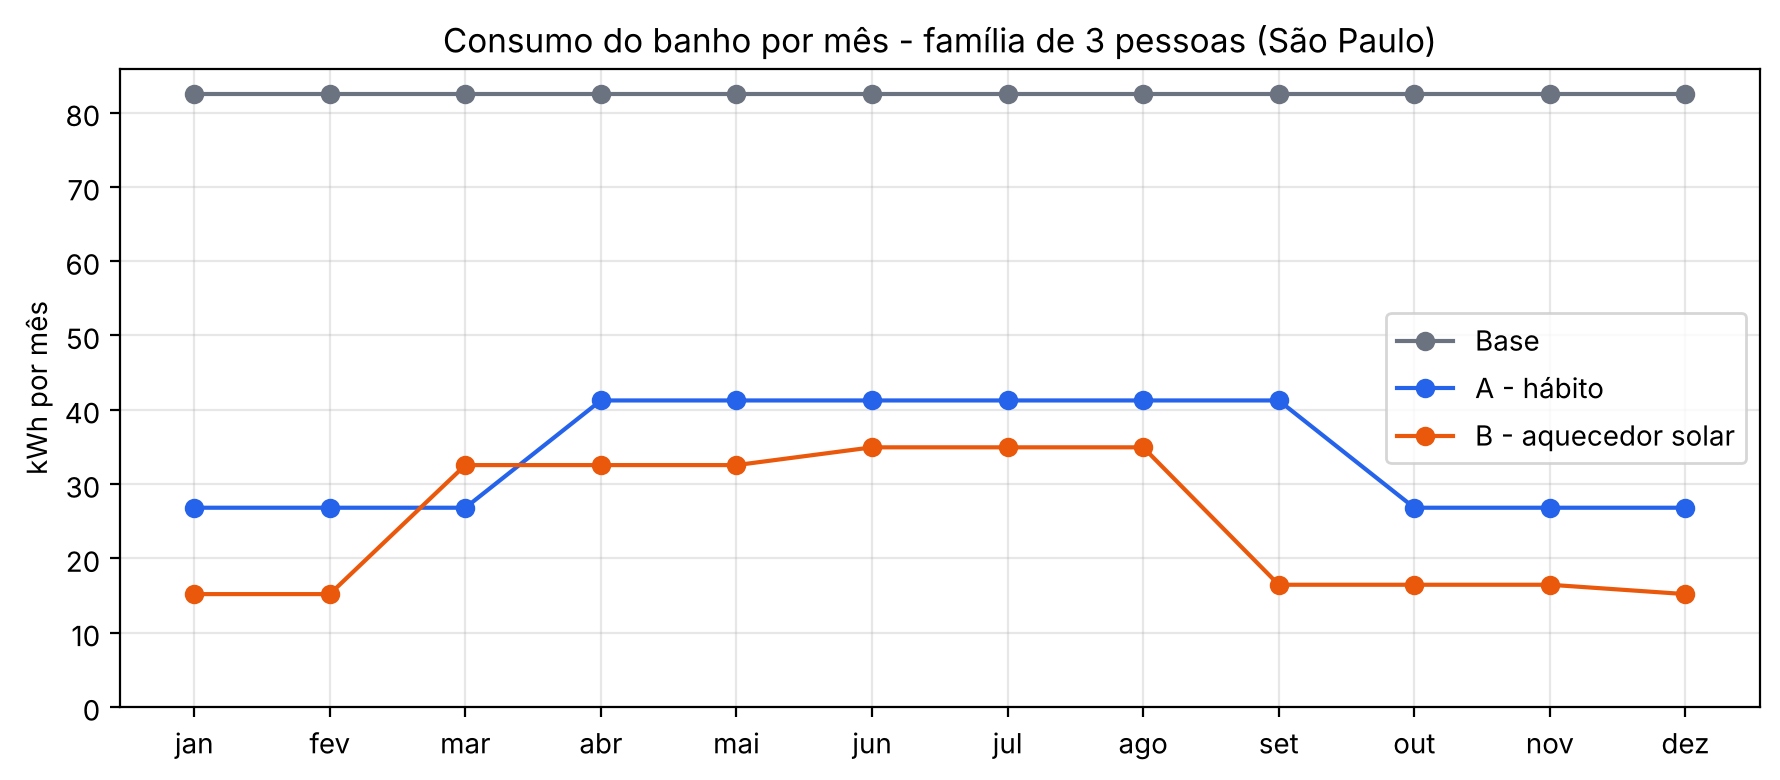

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
x = range(12)
ax.plot(x, mensal["base_kwh"], marker="o", color="#6b7280", label="Base")
ax.plot(x, mensal["a_kwh"], marker="o", color="#2563eb", label="A - hábito")
ax.plot(x, mensal["b_kwh"], marker="o", color="#ea580c", label="B - aquecedor solar")
ax.set_xticks(list(x), mensal["mes"])
ax.set_ylabel("kWh por mês")
ax.set_ylim(0)
ax.set_title("Consumo do banho por mês - família de 3 pessoas (São Paulo)")
ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("figuras/consumo_mensal.png", dpi=150); plt.show()

## 3.3 Resumo de 12 meses: energia, custo e CO₂

In [6]:
r = ce.resumo_anual(pr)
anual = pd.DataFrame(r.values()).set_index("cenario")
anual[["kwh_ano", "reais_ano", "kg_co2_ano", "economia_kwh", "economia_reais", "economia_pct", "co2_evitado_kg"]]

,kwh_ano,reais_ano,kg_co2_ano,economia_kwh,economia_reais,economia_pct,co2_evitado_kg
cenario,,,,,,,
Base,990.00,"1,009.80",38.12,NaN,NaN,NaN,NaN
A - hábito,408.38,416.54,15.72,581.62,593.26,58.75,22.39
B - aquecedor solar,297.38,303.33,11.45,692.62,706.47,69.96,26.67
A+B - combinado,129.26,131.85,4.98,860.74,877.95,86.94,33.14


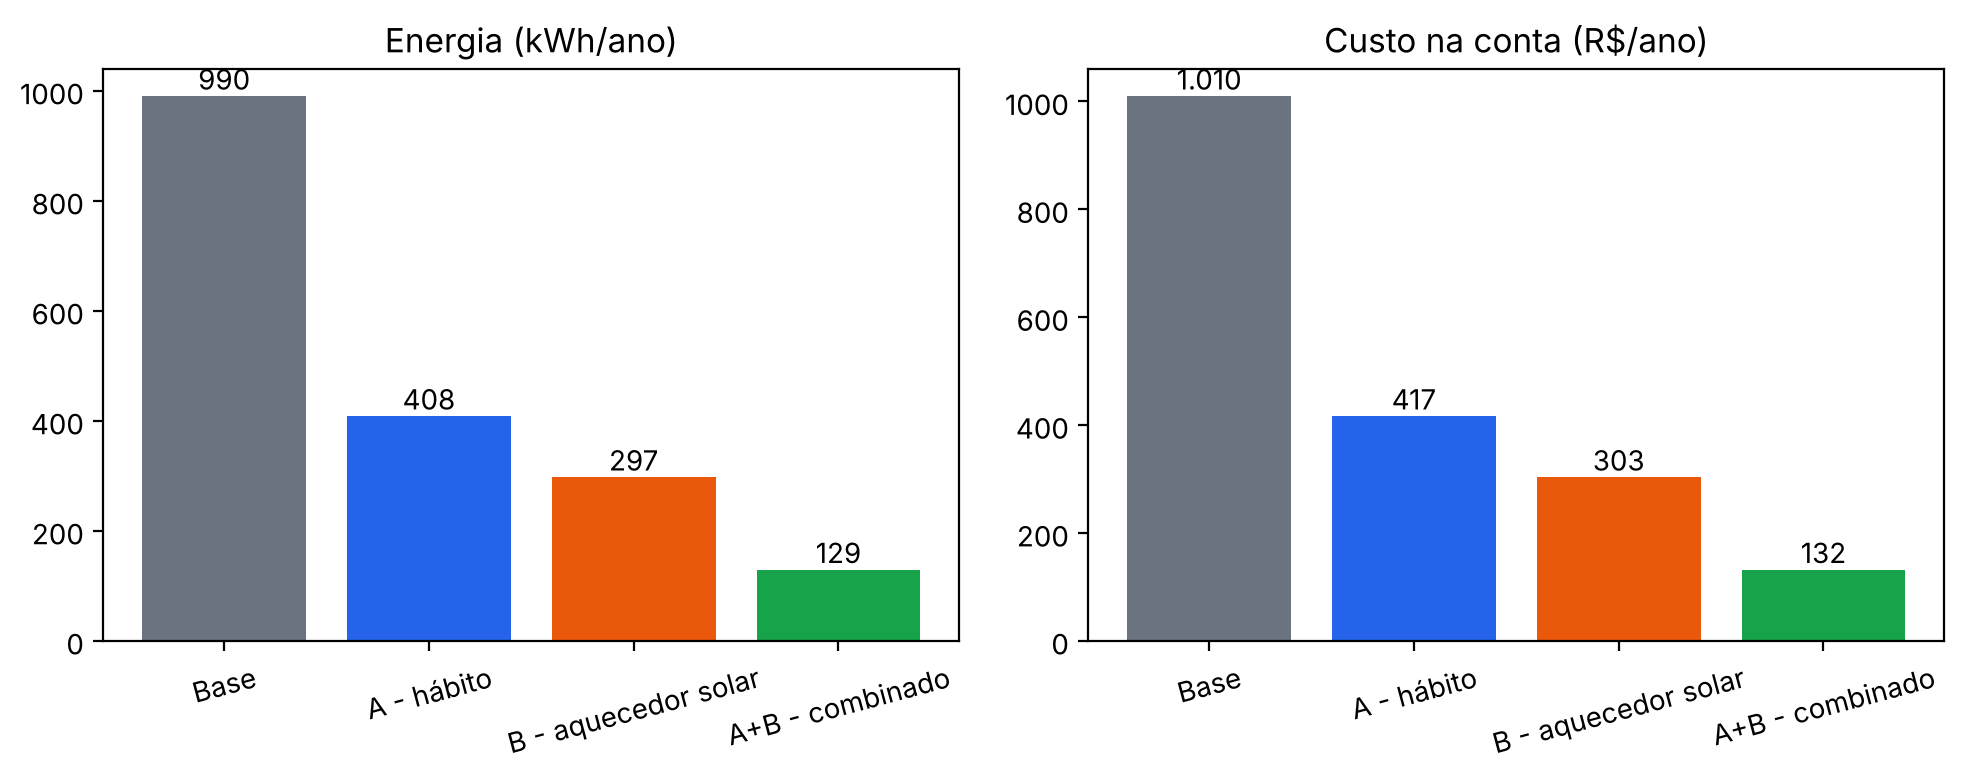

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
cores = ["#6b7280", "#2563eb", "#ea580c", "#16a34a"]
axs[0].bar(anual.index, anual["kwh_ano"], color=cores); axs[0].set_title("Energia (kWh/ano)")
axs[1].bar(anual.index, anual["reais_ano"], color=cores); axs[1].set_title("Custo na conta (R$/ano)")
for a in axs:
    a.tick_params(axis="x", rotation=15)
    for p in a.patches:
        a.annotate(brl(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.savefig("figuras/comparacao_anual.png", dpi=150); plt.show()

## 3.4 Investimento e tempo de retorno (payback)
**Payback simples = investimento ÷ economia por ano**, sem juros e sem reajuste de tarifa.
A alternativa A não tem investimento, então o retorno é imediato.

In [8]:
b = r["b"]
print(f"Economia da alternativa B: R$ {brl(b['economia_reais'])} por ano")
print(f"Investimento: R$ {brl(b['investimento_min'])} a R$ {brl(b['investimento_max'])}")
print(f"Payback: {b['payback_min_anos']:.1f} a {b['payback_max_anos']:.1f} anos  (Idec: 2 a 7 anos)")
anos_vida = 15  # vida útil mínima dos coletores (P17)
print(f"Saldo em {anos_vida} anos: R$ {brl(b['economia_reais']*anos_vida - b['investimento_max'])} "
      f"a R$ {brl(b['economia_reais']*anos_vida - b['investimento_min'])}")

Economia da alternativa B: R$ 706 por ano
Investimento: R$ 2.300 a R$ 4.300
Payback: 3.3 a 6.1 anos  (Idec: 2 a 7 anos)
Saldo em 15 anos: R$ 6.297 a R$ 8.297


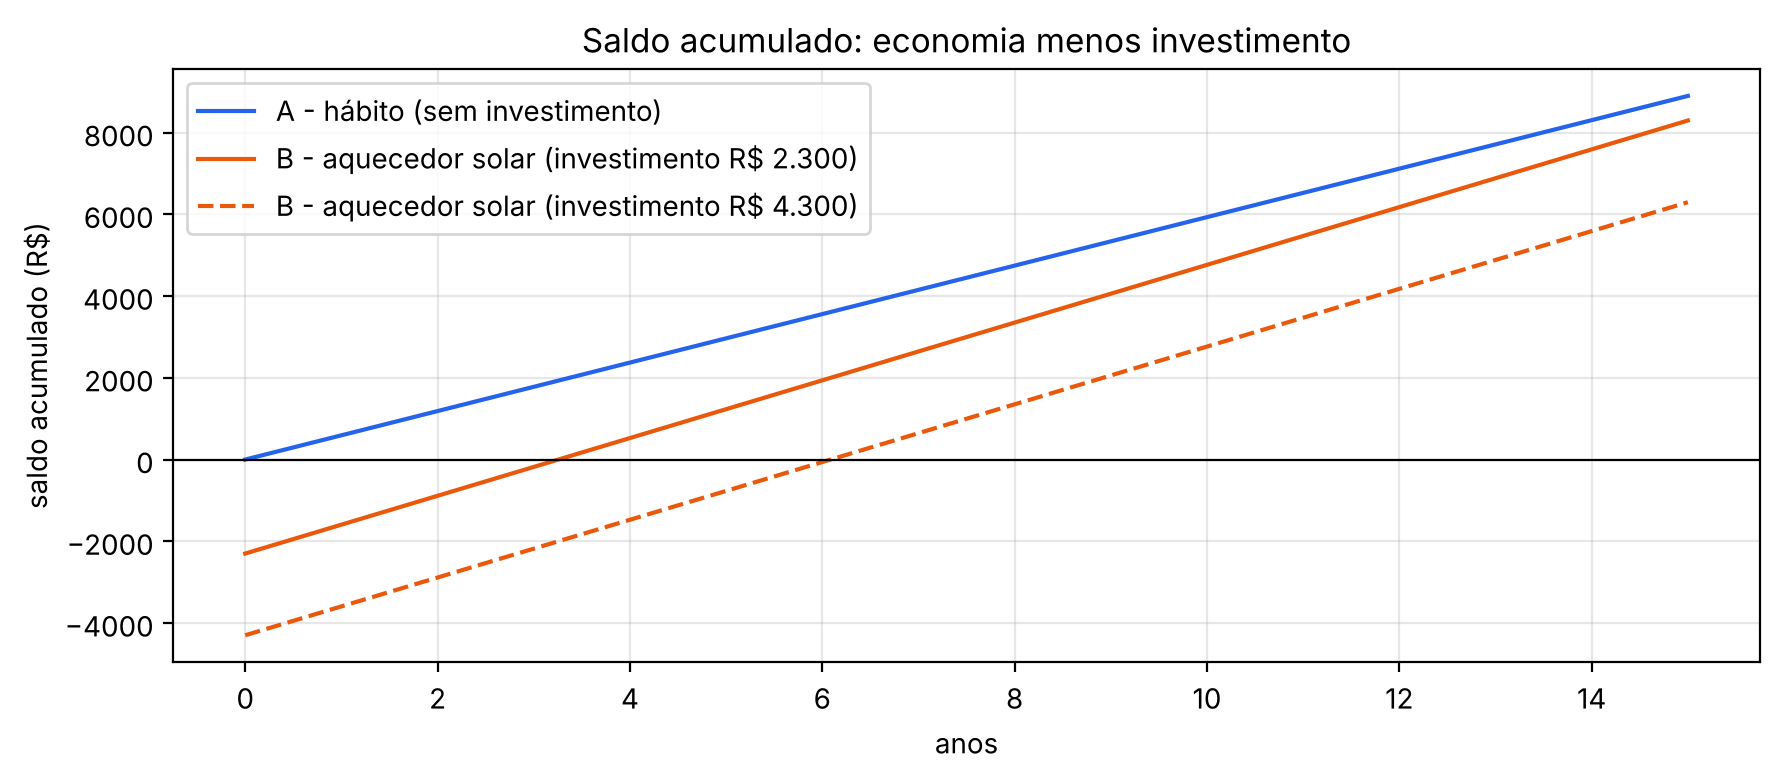

In [9]:
anos = list(range(0, 16))
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(anos, [r["a"]["economia_reais"]*t for t in anos], color="#2563eb", label="A - hábito (sem investimento)")
for inv, est in [(b["investimento_min"], "-"), (b["investimento_max"], "--")]:
    ax.plot(anos, [b["economia_reais"]*t - inv for t in anos], est, color="#ea580c",
            label=f"B - aquecedor solar (investimento R$ {brl(inv)})")
ax.axhline(0, color="black", lw=.8)
ax.set_xlabel("anos"); ax.set_ylabel("saldo acumulado (R$)")
ax.set_title("Saldo acumulado: economia menos investimento")
ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("figuras/payback.png", dpi=150); plt.show()

### E se a família fizer A e B juntas?
Se a família já toma banho de 5 min e usa a posição verão, o aquecedor solar economiza menos em reais, porque sobra menos para economizar. O **payback incremental** mostra quanto tempo o aquecedor leva para se pagar **depois** que o hábito já mudou.

In [10]:
ab = r["ab"]
print(f"A+B: {ab['kwh_ano']:.0f} kWh/ano, economia de {ab['economia_pct']:.0f}% sobre a base (R$ {brl(ab['economia_reais'])}/ano)")
print(f"Ganho extra do aquecedor para quem já faz A: R$ {brl(ab['economia_extra_sobre_a_reais'])}/ano")
print(f"Payback incremental: {ab['payback_incremental_min_anos']:.1f} a {ab['payback_incremental_max_anos']:.1f} anos "
      f"(vida útil dos coletores: 15 a 25 anos)")

A+B: 129 kWh/ano, economia de 87% sobre a base (R$ 878/ano)
Ganho extra do aquecedor para quem já faz A: R$ 285/ano
Payback incremental: 8.1 a 15.1 anos (vida útil dos coletores: 15 a 25 anos)


## 3.5 Efeito da Tarifa Social (Lei 15.235/2025)
Famílias do CadÚnico com renda de até ½ salário mínimo por pessoa **não pagam a energia até 80 kWh/mês** e pagam o excedente.
Como não sabemos quanto o resto da casa consome (geladeira, luz, TV...), testamos três valores **estimados** para os "outros usos".

In [11]:
tarifa = ce.v(pr, "P11")
banho_mes = {k: r[k]["kwh_ano"] / 12 for k in ("base", "a", "b")}
linhas = []
for outros in (0, 50, 100):
    linha = {"outros usos (kWh/mês)": outros}
    for k, nome in [("base", "Base"), ("a", "A"), ("b", "B")]:
        total = banho_mes[k] + outros
        linha[f"{nome}: conta normal (R$)"] = total * tarifa
        linha[f"{nome}: com Tarifa Social (R$)"] = ce.custo_energia_tarifa_social(total, tarifa)
    linhas.append(linha)
tarifa_social = pd.DataFrame(linhas).set_index("outros usos (kWh/mês)")
tarifa_social.T

outros usos (kWh/mês),0,50,100
Base: conta normal (R$),84.15,135.15,186.15
Base: com Tarifa Social (R$),2.55,53.55,104.55
A: conta normal (R$),34.71,85.71,136.71
A: com Tarifa Social (R$),0.00,4.11,55.11
B: conta normal (R$),25.28,76.28,127.28
B: com Tarifa Social (R$),0.00,0.00,45.68


Com a Tarifa Social, o banho "base" sozinho (~82,5 kWh/mês) já passa da faixa gratuita. Em qualquer casa com outros aparelhos, cada kWh economizado no banho sai da parte cobrada da conta. **A economia em reais por kWh continua a mesma.** O que muda é que a conta total fica bem menor.

## 3.6 Sensibilidade: e se as premissas mudarem?
Variamos uma premissa por vez e olhamos a economia anual e o payback de B.

In [12]:
import copy
def com(pr, **mudancas):
    novo = copy.deepcopy(pr)
    for id_, valor in mudancas.items():
        novo[id_]["valor"] = valor
    return novo

testes = [
    ("Referência", {}, {}),
    ("Tarifa -20% (R$ 0,82)", {}, {"tarifa": tarifa*0.8}),
    ("Tarifa +20% (R$ 1,22)", {}, {"tarifa": tarifa*1.2}),
    ("Banho base de 8 min", {}, {"minutos_base": 8}),
    ("Banho base de 15 min", {}, {"minutos_base": 15}),
    ("2 pessoas", {}, {"pessoas": 2}),
    ("4 pessoas", {}, {"pessoas": 4}),
    ("Fração solar 55%", {"P14": 55}, {}),
    ("Fração solar 80%", {"P14": 80}, {}),
    ("Posição verão economiza 30%", {"P07": 30}, {}),
    ("Posição verão economiza 40%", {"P07": 40}, {}),
]
linhas = []
for nome, prem, args in testes:
    rr = ce.resumo_anual(com(pr, **prem), **args)
    linhas.append({"cenário de teste": nome,
                   "economia A (R$/ano)": rr["a"]["economia_reais"],
                   "economia B (R$/ano)": rr["b"]["economia_reais"],
                   "payback B mín (anos)": rr["b"]["payback_min_anos"],
                   "payback B máx (anos)": rr["b"]["payback_max_anos"]})
sens = pd.DataFrame(linhas).set_index("cenário de teste")
sens

,economia A (R$/ano),economia B (R$/ano),payback B mín (anos),payback B máx (anos)
cenário de teste,,,,
Referência,593.26,706.47,3.26,6.09
"Tarifa -20% (R$ 0,82)",474.61,565.18,4.07,7.61
"Tarifa +20% (R$ 1,22)",711.91,847.77,2.71,5.07
Banho base de 8 min,391.30,565.18,4.07,7.61
Banho base de 15 min,"1,098.16","1,059.71",2.17,4.06
2 pessoas,395.50,470.98,4.88,9.13
4 pessoas,791.01,941.97,2.44,4.56
Fração solar 55%,593.26,555.09,4.14,7.75
Fração solar 80%,593.26,807.40,2.85,5.33


## 3.7 Conferência física do aquecedor solar
Quanta energia o sol precisa entregar por dia na alternativa B, e qual é a área mínima de coletor, considerando 100% de aproveitamento (limite teórico)?

In [13]:
energia_solar_dia = r["b"]["economia_kwh"] / (12 * ce.v(pr, "P09"))
area_minima = energia_solar_dia / ce.v(pr, "P20")
print(f"Energia vinda do sol: {energia_solar_dia:.2f} kWh por dia")
print(f"Área teórica mínima de coletor: {area_minima:.2f} m² (sol médio de {ce.v(pr, 'P20')} kWh/m².dia)")
print("Kits de 200 L usam 1,7 a 2,8 m² de coletor (Altoé et al., 2012) -> a área cobre as perdas reais.")

Energia vinda do sol: 1.92 kWh por dia
Área teórica mínima de coletor: 0.42 m² (sol médio de 4.59 kWh/m².dia)
Kits de 200 L usam 1,7 a 2,8 m² de coletor (Altoé et al., 2012) -> a área cobre as perdas reais.


## 3.8 Exportar resultados (usados no README, no vídeo e no assistente)

In [14]:
mensal.to_csv("resultados/resultados_mensais.csv", index=False)
anual.to_csv("resultados/resultados_anuais.csv")
sens.to_csv("resultados/sensibilidade.csv")
tarifa_social.to_csv("resultados/tarifa_social.csv")
print("Exemplo do que o assistente usa (10 min, 3 pessoas):")
ce.estimar_para_usuario(10, 3, pr)

Exemplo do que o assistente usa (10 min, 3 pessoas):


{'kwh_mes_atual': 82,
 'reais_mes_atual': 84,
 'a_minutos': 5.0,
 'a_economia_reais_mes': 49,
 'a_economia_pct': 59,
 'b_economia_reais_mes': 59,
 'b_economia_pct': 70,
 'b_investimento': (2300, 4300),
 'b_payback_anos': (3.3, 6.1),
 'tarifa': 1.02,
 'potencia_w': 5500.0}

## 3.9 O que os cálculos mostram
Família de 3 pessoas em São Paulo, 12 meses, tarifa estimada de R$ 1,02/kWh.

| | kWh/ano | R$/ano | Economia | Investimento | Payback | CO₂ evitado |
|---|---|---|---|---|---|---|
| Base | 990 | ~1.010 | — | — | — | — |
| A - hábito | 408 | ~417 | 59% (~R$ 593/ano) | R$ 0 | imediato | 22 kg/ano |
| B - aquecedor solar | 297 | ~303 | 70% (~R$ 706/ano) | R$ 2.300 a 4.300 | 3,3 a 6,1 anos | 27 kg/ano |
| A+B - combinado | 129 | ~132 | 87% (~R$ 878/ano) | R$ 2.300 a 4.300 | 8,1 a 15,1 anos (depois de A) | 33 kg/ano |

1. **A alternativa A dá quase a mesma economia que a B, sem custo nenhum.** Por isso é a primeira recomendação para o público de baixa renda.
2. **B economiza mais, mas exige investimento.** Ela se paga em 3 a 6 anos, dentro da vida útil dos coletores (15 a 25 anos). Em 15 anos, o saldo fica entre R$ 6.300 e R$ 8.300.
3. **A e B juntas economizam 87%, mas o aquecedor rende menos para quem já mudou o hábito.** Depois de A, o ganho extra de B é de ~R$ 285/ano, e o payback incremental sobe para 8 a 15 anos, perto da vida útil mínima dos coletores. Para a família de referência, B só compensa bem com investimento baixo, família maior ou banhos longos.
4. **O resultado depende dos hábitos.** Para quem toma banho de 15 minutos, a mudança de hábito economiza mais que o aquecedor solar. Para 2 pessoas, o payback de B pode chegar a 9 anos.
5. **Tarifa Social:** a economia por kWh continua a mesma enquanto a casa consome mais de 80 kWh/mês, o que é o caso quando há outros aparelhos.
6. **Impacto ambiental:** o CO₂ evitado é pequeno (22 a 27 kg/ano), porque a eletricidade brasileira é majoritariamente renovável. O ganho maior é reduzir carga no **horário de pico** (fim da tarde), quando o chuveiro elétrico mais pesa para o sistema.

**Limitações:** potência, tempo de banho e fração solar são médias; o payback não considera juros nem reajuste de tarifa; a bandeira tarifária e a iluminação pública ficaram de fora; a sazonalidade da fração solar é uma aproximação pela irradiação de cada estação. A discussão completa fica na etapa 4.